# REST와 페이지네이션

**이 노트북에서 할 일**

1. 이 컴퓨터 안에 켠 연습용 주문 서비스에 HTTP 요청을 보내고, 응답의 상태 코드와 JSON 본문을 읽습니다.
2. 페이지 번호를 바꿔 요청하며, 마지막 페이지에서 다음 페이지 번호가 비는 것을 확인합니다.
3. 첫 페이지만 읽은 함수가 오류 없이 주문을 빠뜨리는 장면을 보고, 다음 페이지 번호를 따라 끝까지 읽도록 고칩니다.

**준비물** — API 키 불필요. 인터넷에 있는 서비스는 쓰지 않습니다.
노트북이 이 컴퓨터 안에 연습용 주문 서비스를 켰다가 마지막 셀에서 끕니다.
모델 호출은 0번이고 비용은 들지 않습니다. 실행 시간은 1분 이내입니다.

**기준 httpx 버전** — 실습 폴더에 고정한 httpx 0.28.1을 씁니다. 교재 출력도 이 버전과 Python 3.12.13으로 만들었습니다.
이 버전의 httpx는 Python 3.8 이상에서 설치됩니다. 오류 메시지 글은 httpx 버전에 따라 다를 수 있습니다.

실습 폴더의 `uv.lock`이 httpx를 0.28.1로 고정하므로, `uv sync --locked`로 만든 환경에는 이 버전이 설치됩니다.
다른 버전과 httpx 1.0 개발판은 이번에 실행하지 않았습니다.

실습 폴더 `labs/part1/ch04-data-tools`에서 Ch 1 3절처럼 `uv sync --locked`로 환경을 만듭니다.
커널에서 이 폴더의 `.venv`를 고른 뒤 첫 셀부터 순서대로 실행합니다.

## 오늘 볼 그림

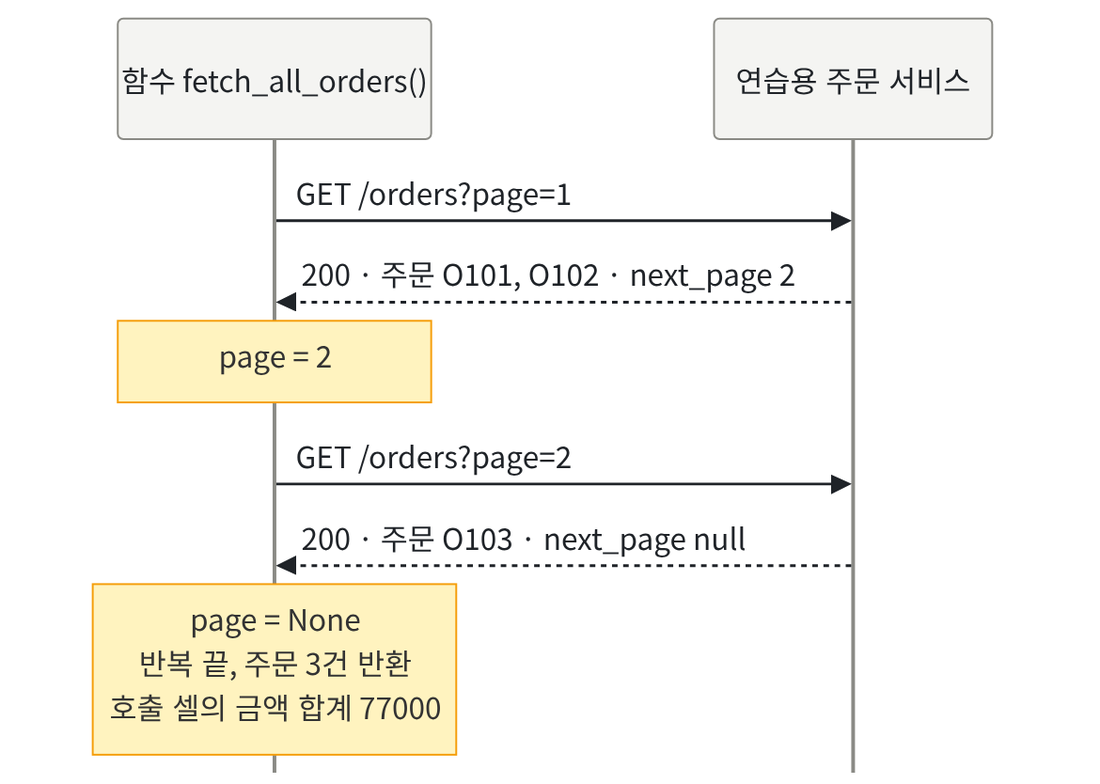

위에서 아래로 읽습니다. 왼쪽 세로선은 이 노트북 끝에서 만드는 함수이고, 오른쪽 세로선은 연습용 주문 서비스입니다.
실선 화살표는 요청, 점선 화살표는 응답입니다. 첫 응답의 다음 페이지 2가 둘째 요청의 page 값이 됩니다.

둘째 응답의 다음 페이지가 null이라 함수는 더 요청하지 않습니다. 첫 노란 메모는 다음 요청에 넣을 페이지 번호이고, 마지막 노란 메모는 반복이 끝난 뒤의 결과입니다.

## 1. 준비

이 노트북은 연습용 서비스가 쓸 파일 세 개를 만듭니다. 01~03절처럼 빈 임시 폴더를 만들고, 그 폴더로 작업 위치를 옮깁니다.
실습 폴더에는 파일이 생기지 않습니다.

코드의 import 두 줄은 Ch 2 07절에서 배운 import 문입니다. 표준 라이브러리 모듈 os와 tempfile을 불러옵니다.

In [1]:
# 연습용 서비스 파일을 둘 빈 임시 폴더를 만들고, 그 폴더로 작업 위치를 옮깁니다
import os
import tempfile

# mkdtemp()는 운영체제 임시 폴더 안에 새 폴더를 만들고 그 경로를 반환합니다
practice_folder = tempfile.mkdtemp(prefix="ch04-04-")
# chdir()는 터미널의 cd처럼 현재 작업 폴더를 옮깁니다
os.chdir(practice_folder)
file_names = os.listdir()
print("현재 작업 폴더의 파일:", file_names)

현재 작업 폴더의 파일: []


**결과 읽기** — 현재 작업 폴더의 파일은 `[]`로, 빈 폴더에서 시작합니다.
폴더의 경로는 컴퓨터마다 달라서 출력하지 않았습니다.

## 2. 연습용 주문 서비스 켜기 — 준비 코드

이 절은 인터넷에 있는 실제 서비스 대신, 이 컴퓨터 안에 켠 연습용 주문 서비스에 요청을 보냅니다.
인터넷 서비스는 내용이 바뀌거나 접속이 막힐 수 있습니다. 매번 같은 결과를 보려고 연습용 서비스를 씁니다.

아래 세 셀은 **연습용 서버를 켜는 준비 코드**이며, 줄마다 읽지 않아도 됩니다. 셀마다 하는 일만 확인하고 차례로 실행합니다.
서버(server)는 요청을 기다렸다가 답을 보내는 프로그램입니다. 서버 쪽 코드를 이해하는 일은 이 절의 목표가 아닙니다.

첫 셀은 서비스가 페이지마다 보낼 주문 목록 글 두 개를 파일로 씁니다. 1쪽에는 주문 두 건, 2쪽에는 한 건이 있습니다.
파일 이름 `page=1.json`은 요청 주소 끝에 붙을 `page=1`에 맞춰 지었습니다. 파일 안의 글 모양은 4절에서 읽습니다.

In [2]:
# 연습용 서비스가 페이지마다 보낼 주문 목록 글 두 개를 파일로 씁니다
# 01~03절의 주문 세 건을 한 페이지에 두 건씩 나눴습니다
page_1_text = """{"orders": [
  {"order_id": "O101", "customer_id": "C001", "amount": 32000},
  {"order_id": "O102", "customer_id": "C002", "amount": 18000}
], "next_page": 2}"""
with open("page=1.json", "w", encoding="utf-8") as file:
    file.write(page_1_text)
page_2_text = """{"orders": [
  {"order_id": "O103", "customer_id": "C001", "amount": 27000}
], "next_page": null}"""
with open("page=2.json", "w", encoding="utf-8") as file:
    file.write(page_2_text)

둘째 셀은 서비스 프로그램 파일 `order_server.py`를 씁니다. 이 프로그램은 요청을 기다리다가, 주소가 `/orders`이고 이름이 맞는 파일이 있으면 그 파일 글을 보냅니다.
맞는 파일이 없으면 「찾을 수 없음」을 보냅니다. 프로그램 글 안의 주석은 궁금한 학생을 위해 달아 두었습니다.

In [3]:
# 요청을 받아 파일 글을 보내는 서비스 프로그램을 order_server.py 파일로 씁니다
server_text = """import os
from wsgiref.simple_server import make_server

# 요청 하나가 올 때마다 이 함수가 불립니다
def answer(environ, start_response):
    # 주소 끝의 쿼리 문자열 page=1로 파일 page=1.json을 고릅니다
    file_name = environ["QUERY_STRING"] + ".json"
    if environ["PATH_INFO"] != "/orders" or not os.path.exists(file_name):
        start_response("404 Not Found", [("Content-Type", "application/json")])
        return [b'{"error": "not found"}']
    start_response("200 OK", [("Content-Type", "application/json")])
    with open(file_name, "rb") as file:
        return [file.read()]

# 포트 번호 0은 운영체제에게 비어 있는 번호를 골라 달라는 뜻입니다
server = make_server("127.0.0.1", 0, answer)
print(server.server_port, flush=True)
server.serve_forever()"""
with open("order_server.py", "w", encoding="utf-8") as file:
    file.write(server_text)

셋째 셀은 그 프로그램을 따로 실행합니다. Ch 2 08절의 `subprocess.run()`은 프로그램이 끝날 때까지 기다렸습니다.
이 셀의 `subprocess.Popen()`은 프로그램을 켜 둔 채 바로 다음 줄로 넘어갑니다.
서비스는 켜지면서 포트 번호를 한 줄 출력하고, 셀은 그 줄을 읽어 서비스 주소를 만듭니다.

인자 `stdout=subprocess.PIPE`는 서비스가 출력한 글을 이 노트북이 읽을 수 있게 이어 둡니다. 메서드 `readline()`은 그 글에서 한 줄을 읽습니다.

In [4]:
# 서비스 프로그램을 따로 실행하고, 서비스가 알려 준 포트 번호로 주소를 만듭니다
import subprocess
import sys

# Popen()은 프로그램을 켜 두고 기다리지 않습니다. 서비스의 접속 기록(stderr)은 버립니다
server_process = subprocess.Popen(
    [sys.executable, "order_server.py"],
    stdout=subprocess.PIPE,
    stderr=subprocess.DEVNULL,
    text=True,
)
# 서비스가 켜지면서 출력한 첫 줄(포트 번호)을 읽습니다
port_text = server_process.stdout.readline().strip()
base_url = f"http://127.0.0.1:{port_text}"
print("서비스 주소:", base_url)
file_names = sorted(os.listdir())
print("현재 작업 폴더의 파일:", file_names)

서비스 주소: http://127.0.0.1:43991
현재 작업 폴더의 파일: ['order_server.py', 'page=1.json', 'page=2.json']


**결과 읽기** — 서비스 주소는 `http://127.0.0.1:`로 시작합니다. 주소 127.0.0.1은 「이 컴퓨터 자신」을 가리킵니다.
콜론 뒤의 숫자는 포트 번호입니다. 포트(port)는 한 컴퓨터 안에서 프로그램마다 나눠 쓰는 번호로, 한 건물 안의 호수와 비슷합니다.
포트 번호는 실행할 때마다 달라서 교재와 다를 수 있습니다.

파일 목록 `['order_server.py', 'page=1.json', 'page=2.json']`은 앞의 두 셀이 쓴 파일입니다. 이제 서비스가 요청을 기다립니다.

## 3. 첫 페이지 요청하기 — HTTP 요청과 상태 코드

프로그램끼리 요청과 응답을 주고받는 약속을 HTTP(HyperText Transfer Protocol)라고 부릅니다.
요청(request)은 「이 주소의 데이터를 주세요」 같은 메시지이고, 응답(response)은 서버가 보내는 답입니다.
식당에서 주문서를 내면 영수증과 음식이 함께 나오는 일과 비슷합니다.

패키지 httpx는 Python에서 HTTP 요청을 보내는 기능 묶음입니다. 실습 폴더에서 실행한 `uv sync --locked`가 이미 설치했습니다.
함수 `httpx.get()`은 읽기 요청인 GET 요청을 보내고, 받은 응답을 객체로 반환합니다.

인자 `params={"page": 1}`은 주소 끝에 `?page=1`을 붙입니다. 물음표 뒤의 `이름=값` 부분을 쿼리 문자열(query string)이라고 부릅니다.
인자 `timeout=2.0`은 연결하기와 응답 읽기 같은 단계마다 최대 2초까지 기다린다는 뜻입니다. 주소는 Ch 3에서 쓴 글자 `+`로 이어 붙입니다.

실행 전에 예상합니다. 요청한 주소 끝에 `/orders?page=1`이 보이고, 상태 코드는 성공을 뜻하는 숫자일 것입니다.

In [5]:
# httpx를 불러와, 주문 목록의 첫 페이지를 달라는 GET 요청을 보냅니다
import httpx

print("httpx 버전:", httpx.__version__)
orders_url = base_url + "/orders"
# get()은 요청을 보내고 응답 객체를 반환합니다. params는 주소 끝의 쿼리 문자열이 됩니다
response = httpx.get(orders_url, params={"page": 1}, timeout=2.0)
print("요청한 주소:", response.url)
print("상태 코드:", response.status_code)

httpx 버전: 0.28.1
요청한 주소: http://127.0.0.1:43991/orders?page=1
상태 코드: 200


**결과 읽기** — 첫 줄 `httpx 버전: 0.28.1`은 실습 폴더에 고정한 버전입니다.
요청한 주소는 서비스 주소 뒤에 `/orders?page=1`이 붙은 모양입니다. 인자 params가 쿼리 문자열을 만들었습니다.

마지막 줄은 `상태 코드: 200`입니다. 상태 코드(status code)는 서버가 요청을 어떻게 처리했는지 알리는 세 자리 숫자입니다.
200은 요청이 성공했다는 뜻입니다.

## 4. 응답 본문 읽기 — JSON

응답에는 상태 코드 말고 본문(body)도 들어 있습니다. 식당 비유에서 영수증이 상태 코드라면, 음식이 본문입니다.
속성 `response.text`에는 본문이 글 그대로 들어 있습니다.

이 서비스의 본문은 JSON(JavaScript Object Notation) 형식입니다. 이 형식은 딕셔너리와 목록 같은 값을 정해진 모양의 글로 적습니다.
택배 송장처럼 칸 모양이 정해져 있어서, 받는 프로그램이 칸마다 값을 꺼낼 수 있습니다.
메서드 `response.json()`은 JSON 글을 Python 딕셔너리와 목록으로 바꿔 반환합니다.

실행 전에 예상합니다. 본문 글은 준비 셀에서 쓴 `page=1.json`의 글과 같고, 바꾼 값은 딕셔너리일 것입니다.

In [6]:
# 응답 본문을 글 그대로 보고, JSON 글을 Python 딕셔너리로 바꿉니다
print("본문 글:", response.text)
# json()은 본문의 JSON 글을 딕셔너리와 목록으로 바꿔 반환합니다
body = response.json()
print("바꾼 값의 자료형:", type(body))
print("이 페이지의 주문 수:", len(body["orders"]))
print("다음 페이지 번호:", body["next_page"])

본문 글: {"orders": [
  {"order_id": "O101", "customer_id": "C001", "amount": 32000},
  {"order_id": "O102", "customer_id": "C002", "amount": 18000}
], "next_page": 2}
바꾼 값의 자료형: <class 'dict'>
이 페이지의 주문 수: 2
다음 페이지 번호: 2


**결과 읽기** — 본문 글은 `{"orders": [`로 시작해 `"next_page": 2}`로 끝납니다. 준비 셀의 파일 글 그대로입니다.
자료형은 `<class 'dict'>`로, 글이 딕셔너리로 바뀌었습니다.

출력의 `이 페이지의 주문 수: 2`와 `다음 페이지 번호: 2`를 봅니다. 01~03절의 주문은 세 건인데, 이 응답에는 두 건만 있습니다.
서비스가 긴 목록을 페이지로 나누고, 다음 페이지가 2번이라고 알려 준 것입니다.
이렇게 긴 목록을 여러 응답으로 나눠 주는 방식을 페이지네이션(pagination)이라고 부릅니다.

## 5. 값 하나 바꿔 보기 — 페이지 2

페이지 번호만 1에서 2로 바꿔 같은 주소에 요청합니다. 앞 응답이 알려 준 다음 페이지 번호를 그대로 넣은 셈입니다.

JSON에서 「값 없음」은 `null`로 적습니다. 메서드 `json()`은 이 값을 Ch 2 04절에서 본 Python의 `None`으로 바꿉니다.

실행 전에 예상합니다. 준비 셀의 `page=2.json`처럼 주문 O103 한 건이 오고, 다음 페이지 번호는 `None`일 것입니다.

In [7]:
# 페이지 번호만 2로 바꿔 요청하고, 본문을 딕셔너리로 바꿉니다
response = httpx.get(orders_url, params={"page": 2}, timeout=2.0)
print("상태 코드:", response.status_code)
print("본문 글:", response.text)
body = response.json()
print("이 페이지의 주문:", body["orders"])
print("다음 페이지 번호:", body["next_page"])

상태 코드: 200
본문 글: {"orders": [
  {"order_id": "O103", "customer_id": "C001", "amount": 27000}
], "next_page": null}
이 페이지의 주문: [{'order_id': 'O103', 'customer_id': 'C001', 'amount': 27000}]
다음 페이지 번호: None


**결과 읽기** — 상태 코드는 이번에도 `200`입니다. 본문 글 끝은 `"next_page": null}`입니다.
딕셔너리로 바꾼 뒤에는 `다음 페이지 번호: None`으로, JSON의 null이 Python의 None이 되었습니다.

이 페이지의 주문은 `'O103'` 한 건입니다. 다음 페이지 번호가 비었으니 이 페이지가 마지막입니다.

## 6. 없는 페이지 요청하기 — 상태 코드 404

마지막 페이지 다음인 3번을 요청해 봅니다. 준비 셀에서 `page=3.json` 파일을 쓰지 않아서, 서비스는 「찾을 수 없음」을 보냅니다.

메서드 `raise_for_status()`는 응답의 상태 코드를 확인합니다. 200번대면 그냥 넘어가고, 그 밖의 번호면 오류 HTTPStatusError를 냅니다.
이 오류 이름은 httpx 안에 있어서, 03절 `sqlite3.IntegrityError`처럼 `httpx.HTTPStatusError`로 적습니다.
Ch 2 05절처럼 이 오류 이름만 받는 `try/except`로 감싸 셀을 끝까지 실행합니다.

실행 전에 예상합니다. 상태 코드는 200이 아니고, 상태 오류 메시지가 출력될 것입니다.

In [8]:
# 없는 페이지 3을 요청하고, 상태 코드가 성공이 아니면 오류를 내게 합니다
response = httpx.get(orders_url, params={"page": 3}, timeout=2.0)
print("상태 코드:", response.status_code)
print("본문 글:", response.text)
try:
    response.raise_for_status()
except httpx.HTTPStatusError as error:
    print("상태 오류:", error)

상태 코드: 404
본문 글: {"error": "not found"}
상태 오류: Client error '404 Not Found' for url 'http://127.0.0.1:43991/orders?page=3'
For more information check: https://developer.mozilla.org/en-US/docs/Web/HTTP/Status/404


**결과 읽기** — 상태 코드는 `404`이고, 본문 글은 `{"error": "not found"}`입니다. 404는 요청한 데이터를 찾을 수 없다는 뜻입니다.
상태 오류 메시지는 `Client error '404 Not Found'`로 시작합니다. 4로 시작하는 상태 코드는 요청한 쪽의 문제로 봅니다.

이 본문에는 주문 목록 칸 `orders`가 없습니다. 상태 코드를 확인하지 않고 이 칸을 꺼내는 경우는 이번에 실행하지 않았습니다.
뒤의 두 함수는 본문을 읽기 전에 `raise_for_status()`를 불러 상태 코드부터 확인합니다.

## 7. Before — 첫 페이지만 읽는 함수

이제 3~6절에서 한 일을 함수로 묶습니다. 01절 `fetch_orders()`와 03절 `find_customer_orders()`처럼 딕셔너리 목록을 반환합니다.
이런 함수가 에이전트 도구가 되면, 모델은 함수가 반환한 목록을 보고 답을 만듭니다.

Before 함수는 페이지 1을 요청하고, 상태 코드를 확인하고, 그 페이지의 주문 목록을 반환합니다.
요청한 페이지와 응답의 다음 페이지 번호는 함수 안에서 출력합니다.

실행 전에 예상합니다. 함수를 정의만 하는 셀이라 출력은 없을 것입니다.

In [9]:
# Before: 첫 페이지만 요청해, 그 페이지의 주문 목록을 반환합니다
def fetch_orders_before(orders_url: str) -> list:
    page = 1
    response = httpx.get(orders_url, params={"page": page}, timeout=2.0)
    # 상태 코드가 200번대가 아니면 여기서 오류가 납니다
    response.raise_for_status()
    body = response.json()
    print("요청한 페이지:", page, "/ 다음 페이지 번호:", body["next_page"])
    return body["orders"]

**결과 읽기** — 출력이 없습니다. 함수 `fetch_orders_before()`가 정의되었습니다.

함수를 부르고, 반환된 주문의 금액을 Ch 2 03절의 `+=`로 더합니다.
실행 전에 예상합니다. 맞게 읽었다면 주문은 세 건이고, 합계는 01절 전체 합계와 같은 77000이어야 합니다.

In [10]:
# Before: 함수가 반환한 주문을 출력하고 금액 합계를 냅니다
before_orders = fetch_orders_before(orders_url)
before_total = 0
for order in before_orders:
    print("읽은 주문:", order["order_id"], order["amount"])
    before_total += order["amount"]
print("읽은 주문 수:", len(before_orders))
print("금액 합계:", before_total)

요청한 페이지: 1 / 다음 페이지 번호: 2
읽은 주문: O101 32000
읽은 주문: O102 18000
읽은 주문 수: 2
금액 합계: 50000


**결과 읽기** — 셀은 오류 없이 끝났고, 상태 코드 확인도 통과했습니다. 그런데 `읽은 주문 수: 2`, `금액 합계: 50000`입니다.
01절에서 확인한 전체 합계 77000보다 27000원 적습니다. 2쪽에 있던 주문 O103이 빠졌습니다.

첫 줄 `요청한 페이지: 1 / 다음 페이지 번호: 2`는 뒤에 페이지가 더 있다고 알려 줍니다. 함수가 이 값을 쓰지 않고 끝났습니다.
에이전트 도구라면 모델은 주문이 두 건뿐이라고 답하게 됩니다. 반환된 목록만 보고는 빠진 주문이 있는지 알 수 없습니다.

## 8. After — 다음 페이지 번호가 없을 때까지 읽는 함수

After 함수는 요청할 페이지 번호를 변수 `page`에 두고, Ch 2 02절의 `while` 반복으로 요청을 이어 갑니다.
한 번 돌 때마다 받은 주문을 목록에 `append()`로 모으고, 응답의 다음 페이지 번호를 `page`에 다시 넣습니다.

마지막 페이지의 다음 페이지 번호는 `None`입니다. 반복 조건 `page is not None`이 거짓이 되어 반복이 끝나고, 모은 목록을 반환합니다.

실행 전에 예상합니다. 함수를 정의만 하는 셀이라 출력은 없을 것입니다.

In [11]:
# After: 다음 페이지 번호가 None이 될 때까지 차례로 요청해, 모든 주문을 모아 반환합니다
def fetch_all_orders(orders_url: str) -> list:
    all_orders = []
    page = 1
    while page is not None:
        response = httpx.get(orders_url, params={"page": page}, timeout=2.0)
        response.raise_for_status()
        body = response.json()
        print("요청한 페이지:", page, "/ 다음 페이지 번호:", body["next_page"])
        for order in body["orders"]:
            all_orders.append(order)
        # 응답이 알려 준 다음 페이지 번호로 바꿉니다. 마지막 페이지에서는 None입니다
        page = body["next_page"]
    return all_orders

**결과 읽기** — 출력이 없습니다. 함수 `fetch_all_orders()`가 정의되었습니다.
요청하고, 상태 코드를 확인하고, 본문을 읽는 줄은 Before 함수와 같습니다. 반복과 모으기 줄만 더했습니다.

같은 주소로 함수를 부르고 금액을 더합니다.
실행 전에 예상합니다. 페이지 1과 2를 요청한 줄이 출력되고, 주문 세 건과 합계 77000이 나올 것입니다.

In [12]:
# After: 함수가 반환한 주문을 출력하고 금액 합계를 냅니다
all_orders = fetch_all_orders(orders_url)
after_total = 0
for order in all_orders:
    print("읽은 주문:", order["order_id"], order["amount"])
    after_total += order["amount"]
print("읽은 주문 수:", len(all_orders))
print("금액 합계:", after_total)
assert after_total == 77000

요청한 페이지: 1 / 다음 페이지 번호: 2
요청한 페이지: 2 / 다음 페이지 번호: None
읽은 주문: O101 32000
읽은 주문: O102 18000
읽은 주문: O103 27000
읽은 주문 수: 3
금액 합계: 77000


**결과 읽기** — 요청 줄이 두 번 출력되었습니다. 첫 줄은 `요청한 페이지: 1 / 다음 페이지 번호: 2`입니다.
둘째 줄은 `요청한 페이지: 2 / 다음 페이지 번호: None`입니다. 이어서 `읽은 주문 수: 3`과 `금액 합계: 77000`이 나왔습니다.
합계가 01절 전체 합계와 같고, 검사 줄 `assert`도 멈추지 않았습니다.

함수는 페이지 3을 요청하지 않았습니다. 6절처럼 없는 페이지에 부딪혀 멈춘 것이 아닙니다.
응답이 알려 준 다음 페이지 번호가 비어서 반복을 끝냈습니다.

## 9. 연습용 서비스 끄기

연습이 끝났으니 2절에서 켠 서비스를 끕니다. 메서드 `terminate()`는 따로 실행한 프로그램에 멈추라는 신호를 보냅니다.
메서드 `wait()`는 그 프로그램이 끝날 때까지 기다립니다. 메서드 `poll()`은 프로그램이 아직 실행 중이면 `None`을 반환합니다.

실행 전에 예상합니다. 서비스가 아직 켜져 있는지 묻는 줄에 `False`가 나올 것입니다.

In [13]:
# 2절에서 켠 연습용 주문 서비스를 끄고, 꺼질 때까지 기다립니다
server_process.terminate()
server_process.wait()
# poll()이 None이 아니면 프로그램이 끝난 것입니다
print("서비스가 아직 켜져 있는가:", server_process.poll() is None)

서비스가 아직 켜져 있는가: False


**결과 읽기** — 출력은 `서비스가 아직 켜져 있는가: False`입니다. 연습용 서비스가 꺼졌습니다.
꺼진 서비스 주소로 요청을 보내는 경우는 이번에 실행하지 않았습니다. 다시 연습하려면 첫 셀부터 차례로 실행합니다.

## 정리

- HTTP 요청은 주소와 쿼리 문자열로 원하는 데이터를 적고, 응답은 상태 코드와 본문을 보냅니다. 메서드 `json()`은 JSON 본문을 딕셔너리로 바꿉니다.
- 상태 코드가 200번대가 아닌 응답은 `raise_for_status()`가 오류로 알립니다. 없는 페이지 3은 404였습니다.
- 첫 페이지만 읽은 함수는 오류 없이 2건, 합계 50000을 반환했습니다. 다음 페이지 번호가 `None`이 될 때까지 읽은 함수는 3건, 77000이었습니다.

이번에는 Linux의 Python 3.12.13과 httpx 0.28.1로, 이 컴퓨터 안의 연습용 서비스에만 요청했습니다.
인터넷의 실제 서비스와 다른 운영체제에서는 실행하지 않았습니다.
다음 절에서는 JSON 대신 HTML로 된 문서에서 필요한 값을 골라 읽습니다.